# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it.

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16).
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook.

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

6. Implement a new player with the following strategy:

    * Assign each card a value:
        * Cards 2 to 6 are +1
        * Cards 7 to 9 are 0
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings.

In [1]:
#1
import random
from dataclasses import dataclass


@dataclass(frozen=True)
class Card:
    rank: str
    suit: str

    @property
    def value(self):
        if self.rank == "A":
            return 11
        if self.rank in ("J", "Q", "K"):
            return 10
        return int(self.rank)

    @property
    def count_value(self):
        if self.rank in ("2", "3", "4", "5", "6"):
            return 1
        if self.rank in ("7", "8", "9"):
            return 0
        return -1

    def __str__(self):
        return f"{self.rank} of {self.suit}"


class Deck:
    PLASTIC = "PLASTIC CARD"

    def __init__(self, num_decks=6, seed=None):
        if not isinstance(num_decks, int) or num_decks < 1:
            raise ValueError("num_decks must be a positive integer.")

        self.num_decks = num_decks
        self.rng = random.Random(seed)
        self.cards = []
        self.shuffle_needed = False
        self.shuffle()

    def shuffle(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = [
            "2", "3", "4", "5", "6", "7", "8",
            "9", "10", "J", "Q", "K", "A"
        ]

        self.cards = [
            Card(rank, suit)
            for _ in range(self.num_decks)
            for suit in suits
            for rank in ranks
        ]

        self.rng.shuffle(self.cards)

        # Draw from the end of the list. This places the cut card
        # randomly after approximately 60–75% of the shoe is used.
        position = self.rng.randint(
            int(len(self.cards) * 0.25),
            int(len(self.cards) * 0.40)
        )

        self.cards.insert(position, self.PLASTIC)
        self.shuffle_needed = False

    def draw(self):
        while self.cards:
            card = self.cards.pop()

            if card == self.PLASTIC:
                self.shuffle_needed = True
                continue

            return card

        raise RuntimeError("No cards remain in the shoe.")

    def remaining(self):
        return sum(isinstance(card, Card) for card in self.cards)


deck = Deck(num_decks=6, seed=123)

print("Number of playing cards:", deck.remaining())
print("\nFive drawn cards:")

for _ in range(5):
    print(deck.draw())

print("\nPlaying cards remaining:", deck.remaining())

Number of playing cards: 312

Five drawn cards:
2 of Clubs
9 of Clubs
7 of Spades
2 of Hearts
8 of Clubs

Playing cards remaining: 307


In [2]:
#3
class HandSkeleton:
    def __init__(self):
        self.cards = []

    def add(self, card):
        pass

    def total(self):
        pass

    def is_blackjack(self):
        pass

    def is_bust(self):
        pass


class PlayerSkeleton:
    def __init__(self, name, chips=1000):
        self.name = name
        self.chips = chips
        self.initial_chips = chips
        self.hand = None
        self.running_count = 0
        self.hands_played = 0
        self.wins = 0
        self.losses = 0
        self.pushes = 0

    def new_hand(self):
        pass

    def observe(self, card):
        pass

    def reset_count(self):
        pass

    def wants_hit(self, dealer_upcard=None):
        pass


class DealerSkeleton(PlayerSkeleton):
    def wants_hit(self, dealer_upcard=None):
        pass


class HumanPlayerSkeleton(PlayerSkeleton):
    def wants_hit(self, dealer_upcard=None):
        pass


class CountingPlayerSkeleton(PlayerSkeleton):
    def __init__(self, name, chips=1000, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold

    def wants_hit(self, dealer_upcard=None):
        pass


class BlackjackGameSkeleton:
    def __init__(self, players, num_decks=6, bet=10, seed=None):
        self.players = players
        self.deck = None
        self.dealer = None
        self.bet = bet

    def deal_to(self, player, visible=True):
        pass

    def play_round(self, verbose=True):
        pass

    def play(self, rounds=5, verbose=True):
        pass

    def summary(self):
        pass


print("Class skeletons created.")

Class skeletons created.


In [4]:
#4
class Hand:
    def __init__(self):
        self.cards = []

    def add(self, card):
        self.cards.append(card)

    def total(self):
        total = sum(card.value for card in self.cards)
        aces = sum(card.rank == "A" for card in self.cards)

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_blackjack(self):
        return len(self.cards) == 2 and self.total() == 21

    def is_bust(self):
        return self.total() > 21

    def __str__(self):
        cards = ", ".join(str(card) for card in self.cards)
        return f"{cards} | Total: {self.total()}"


class Player:
    def __init__(self, name, chips=1000):
        if chips < 0:
            raise ValueError("Starting chips cannot be negative.")

        self.name = name
        self.chips = float(chips)
        self.initial_chips = float(chips)
        self.hand = Hand()
        self.running_count = 0

        self.hands_played = 0
        self.wins = 0
        self.losses = 0
        self.pushes = 0

    def new_hand(self):
        self.hand = Hand()

    def observe(self, card):
        self.running_count += card.count_value

    def reset_count(self):
        self.running_count = 0

    def wants_hit(self, dealer_upcard=None):
        raise NotImplementedError("Implement a player strategy.")


class Dealer(Player):
    def wants_hit(self, dealer_upcard=None):
        return self.hand.total() < 17


class HumanPlayer(Player):
    def wants_hit(self, dealer_upcard=None):
        print(f"\nYour hand: {self.hand}")
        print(f"Dealer shows: {dealer_upcard}")
        print(f"Running count: {self.running_count}")

        while True:
            choice = input("Hit or stand? Enter h or s: ").strip().lower()

            if choice in ("h", "hit"):
                return True
            if choice in ("s", "stand"):
                return False

            print("Please enter h or s.")


class BlackjackGame:
    def __init__(self, players, num_decks=6, bet=10, seed=None):
        if not players:
            raise ValueError("At least one player is required.")
        if len(players) > 7:
            raise ValueError("Use at most seven players.")
        if len({id(player) for player in players}) != len(players):
            raise ValueError("Each seat must have a separate player object.")
        if bet <= 0:
            raise ValueError("The bet must be positive.")

        # Reserve enough cards to finish a round without reshuffling
        # in the middle of it, even with unusually long hands.
        self.reserve = 22 * (len(players) + 1)

        if num_decks * 52 < self.reserve:
            raise ValueError(
                "Use more decks for this number of players."
            )

        self.players = players
        self.deck = Deck(num_decks, seed)
        self.dealer = Dealer("House Dealer")
        self.bet = float(bet)
        self.round_number = 0

        for player in self.players:
            player.reset_count()

    def expose(self, card):
        # Every seated player sees each exposed card exactly once.
        for player in self.players:
            player.observe(card)

    def deal_to(self, player, visible=True):
        card = self.deck.draw()
        player.hand.add(card)

        if visible:
            self.expose(card)

        return card

    def play_round(self, verbose=True):
        active = [
            player for player in self.players
            if player.chips >= self.bet
        ]

        if not active:
            if verbose:
                print("No player has enough chips to continue.")
            return False

        if (
            self.deck.shuffle_needed
            or self.deck.remaining() < self.reserve
        ):
            self.deck.shuffle()

            for player in self.players:
                player.reset_count()

            if verbose:
                print("\nShoe shuffled. Running counts reset.")

        self.round_number += 1
        self.dealer.new_hand()

        for player in active:
            player.new_hand()
            player.chips -= self.bet
            player.hands_played += 1

        # First card to each player, then the dealer's upcard.
        for player in active:
            self.deal_to(player)

        upcard = self.deal_to(self.dealer)

        # Second card to each player, then the dealer's hidden card.
        for player in active:
            self.deal_to(player)

        hole_card = self.deal_to(self.dealer, visible=False)

        if verbose:
            print(f"\n{'=' * 50}")
            print(f"Round {self.round_number}")
            print(f"Dealer shows: {upcard}")

            for player in active:
                print(f"{player.name}: {player.hand}")

        # A dealer blackjack ends player action immediately.
        if not self.dealer.hand.is_blackjack():
            for player in active:
                while (
                    player.hand.total() < 21
                    and player.wants_hit(upcard)
                ):
                    card = self.deal_to(player)

                    if verbose:
                        print(
                            f"{player.name} hits: {card} "
                            f"| Total: {player.hand.total()}"
                        )

        # Reveal the hidden card after player turns.
        self.expose(hole_card)

        if verbose:
            print(f"Dealer reveals: {hole_card}")

        # The house only needs to draw if a non-blackjack,
        # non-busted player still needs a comparison.
        needs_comparison = any(
            not player.hand.is_bust()
            and not player.hand.is_blackjack()
            for player in active
        )

        if not self.dealer.hand.is_blackjack() and needs_comparison:
            while self.dealer.wants_hit():
                card = self.deal_to(self.dealer)

                if verbose:
                    print(f"Dealer hits: {card}")

        if verbose:
            print(f"Dealer final hand: {self.dealer.hand}")

        for player in active:
            player_total = player.hand.total()
            dealer_total = self.dealer.hand.total()

            if player.hand.is_bust():
                result = "loss"
                payout = 0

            elif self.dealer.hand.is_blackjack():
                if player.hand.is_blackjack():
                    result = "push"
                    payout = self.bet
                else:
                    result = "loss"
                    payout = 0

            elif player.hand.is_blackjack():
                result = "blackjack"
                payout = 2.5 * self.bet

            elif self.dealer.hand.is_bust() or player_total > dealer_total:
                result = "win"
                payout = 2 * self.bet

            elif player_total == dealer_total:
                result = "push"
                payout = self.bet

            else:
                result = "loss"
                payout = 0

            player.chips += payout

            if result in ("win", "blackjack"):
                player.wins += 1
            elif result == "loss":
                player.losses += 1
            else:
                player.pushes += 1

            if verbose:
                net = payout - self.bet
                print(
                    f"{player.name}: {result.upper()} "
                    f"| Net: {net:+.2f} "
                    f"| Chips: {player.chips:.2f}"
                )

        return True

    def play(self, rounds=5, verbose=True):
        for _ in range(rounds):
            if not self.play_round(verbose):
                break

    def summary(self):
        print("\nRESULTS")
        print(
            f"{'Player':<22}"
            f"{'Hands':>8}"
            f"{'Wins':>8}"
            f"{'Losses':>8}"
            f"{'Pushes':>8}"
            f"{'Net chips':>12}"
            f"{'Avg/hand':>12}"
        )

        for player in self.players:
            net = player.chips - player.initial_chips
            average = (
                net / player.hands_played
                if player.hands_played else 0
            )

            print(
                f"{player.name:<22}"
                f"{player.hands_played:>8}"
                f"{player.wins:>8}"
                f"{player.losses:>8}"
                f"{player.pushes:>8}"
                f"{net:>12.2f}"
                f"{average:>12.4f}"
            )



In [5]:
#5
computer_players = [
    Dealer("Computer 1", chips=1000),
    Dealer("Computer 2", chips=1000),
    Dealer("Computer 3", chips=1000)
]

demo_game = BlackjackGame(
    players=computer_players,
    num_decks=6,
    bet=10,
    seed=234
)

demo_game.play(rounds=5, verbose=True)
demo_game.summary()


Round 1
Dealer shows: K of Clubs
Computer 1: 8 of Diamonds, 4 of Hearts | Total: 12
Computer 2: 7 of Clubs, K of Spades | Total: 17
Computer 3: 5 of Clubs, A of Clubs | Total: 16
Computer 1 hits: 5 of Clubs | Total: 17
Computer 3 hits: 10 of Diamonds | Total: 16
Computer 3 hits: 4 of Clubs | Total: 20
Dealer reveals: 2 of Diamonds
Dealer hits: 6 of Spades
Dealer final hand: K of Clubs, 2 of Diamonds, 6 of Spades | Total: 18
Computer 1: LOSS | Net: -10.00 | Chips: 990.00
Computer 2: LOSS | Net: -10.00 | Chips: 990.00
Computer 3: WIN | Net: +10.00 | Chips: 1010.00

Round 2
Dealer shows: 6 of Spades
Computer 1: 2 of Spades, 2 of Diamonds | Total: 4
Computer 2: K of Spades, Q of Clubs | Total: 20
Computer 3: J of Hearts, 5 of Spades | Total: 15
Computer 1 hits: 4 of Spades | Total: 8
Computer 1 hits: J of Hearts | Total: 18
Computer 3 hits: A of Clubs | Total: 16
Computer 3 hits: J of Spades | Total: 26
Dealer reveals: A of Clubs
Dealer final hand: 6 of Spades, A of Clubs | Total: 17
Comp

In [6]:
#6
class CountingPlayer(Player):
    def __init__(self, name, chips=1000, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold

    def wants_hit(self, dealer_upcard=None):
        return (
            self.hand.total() < 21
            and self.running_count < self.threshold
        )


counting_players = [
    Dealer("Dealer strategy", chips=1000),
    CountingPlayer("Count threshold 0", chips=1000, threshold=0),
    CountingPlayer("Count threshold -2", chips=1000, threshold=-2)
]

counting_game = BlackjackGame(
    players=counting_players,
    num_decks=6,
    bet=10,
    seed=345
)

counting_game.play(rounds=5, verbose=True)
counting_game.summary()


Round 1
Dealer shows: 3 of Hearts
Dealer strategy: 4 of Spades, 2 of Hearts | Total: 6
Count threshold 0: 4 of Hearts, 7 of Spades | Total: 11
Count threshold -2: 8 of Clubs, 8 of Clubs | Total: 16
Dealer strategy hits: 3 of Spades | Total: 9
Dealer strategy hits: 8 of Spades | Total: 17
Dealer reveals: K of Diamonds
Dealer hits: 9 of Spades
Dealer final hand: 3 of Hearts, K of Diamonds, 9 of Spades | Total: 22
Dealer strategy: WIN | Net: +10.00 | Chips: 1010.00
Count threshold 0: WIN | Net: +10.00 | Chips: 1010.00
Count threshold -2: WIN | Net: +10.00 | Chips: 1010.00

Round 2
Dealer shows: 9 of Spades
Dealer strategy: K of Diamonds, 2 of Spades | Total: 12
Count threshold 0: 8 of Diamonds, 2 of Hearts | Total: 10
Count threshold -2: 10 of Diamonds, 7 of Diamonds | Total: 17
Dealer strategy hits: A of Spades | Total: 13
Dealer strategy hits: 6 of Spades | Total: 19
Dealer reveals: A of Clubs
Dealer final hand: 9 of Spades, A of Clubs | Total: 20
Dealer strategy: LOSS | Net: -10.00 | 

In [7]:
#testing
simulation_players = [
    Dealer("Dealer strategy", chips=5000),
    CountingPlayer(
        "Count threshold 0",
        chips=5000,
        threshold=0
    ),
    CountingPlayer(
        "Count threshold -2",
        chips=5000,
        threshold=-2
    )
]

simulation = BlackjackGame(
    players=simulation_players,
    num_decks=6,
    bet=10,
    seed=456
)

simulation.play(rounds=10000, verbose=False)
simulation.summary()

print("\nFinal chip balances:")
for player in simulation_players:
    print(f"{player.name}: {player.chips:.2f} chips")


RESULTS
Player                   Hands    Wins  Losses  Pushes   Net chips    Avg/hand
Dealer strategy          10000    4169    4835     996    -4275.00     -0.4275
Count threshold 0         1521     468    1000      53    -5000.00     -3.2873
Count threshold -2        1925     660    1203      62    -4995.00     -2.5948

Final chip balances:
Dealer strategy: 725.00 chips
Count threshold 0: 0.00 chips
Count threshold -2: 5.00 chips


In [8]:
#7
STARTING_CHIPS = 5000
BET = 10


def run_test_game(strategy_class, seed, threshold=None, rounds=50):
    options = {
        "name": "Strategy player",
        "chips": STARTING_CHIPS
    }

    if threshold is not None:
        options["threshold"] = threshold

    strategy_player = strategy_class(**options)

    players = [
        strategy_player,
        Dealer("Computer 1", chips=STARTING_CHIPS),
        Dealer("Computer 2", chips=STARTING_CHIPS),
        Dealer("Computer 3", chips=STARTING_CHIPS)
    ]

    game = BlackjackGame(
        players=players,
        num_decks=6,
        bet=BET,
        seed=seed
    )

    for _ in range(rounds):
        if strategy_player.chips < BET:
            break

        if not game.play_round(verbose=False):
            break

    return strategy_player, game


strategy_player, game = run_test_game(
    strategy_class=CountingPlayer,
    threshold=0,
    seed=123
)

game.summary()

net_winnings = strategy_player.chips - STARTING_CHIPS

print(f"\nStarting chips: {STARTING_CHIPS:.2f}")
print(f"Final chips: {strategy_player.chips:.2f}")
print(f"Net winnings: {net_winnings:+.2f}")
print(f"Rounds played: {strategy_player.hands_played}")


RESULTS
Player                   Hands    Wins  Losses  Pushes   Net chips    Avg/hand
Strategy player             50      16      34       0     -165.00     -3.3000
Computer 1                  50      20      19      11       15.00      0.3000
Computer 2                  50      22      24       4      -15.00     -0.3000
Computer 3                  50      22      23       5       10.00      0.2000

Starting chips: 5000.00
Final chips: 4835.00
Net winnings: -165.00
Rounds played: 50


Number of games: 100
Average final chips: 4812.55
Average net winnings per game: -187.45
SD of net winnings per game: 67.41
Average winnings per round: -3.7490
SD of game-average winnings per round: 1.3483

Estimated probability of net winning: 1.0%
Estimated probability of net losing: 99.0%
Estimated probability of breaking even: 0.0%


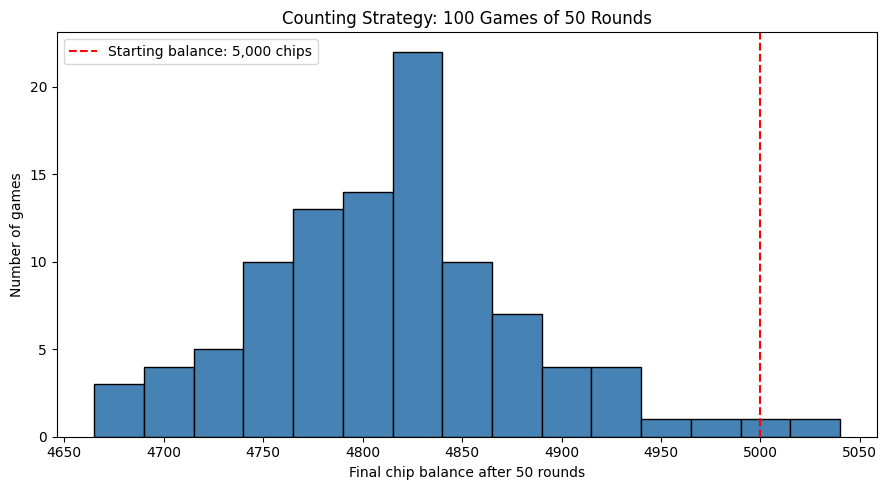

In [9]:
#8
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def run_experiment(strategy_class, threshold=None,
                   games=100, rounds=50, seed_start=1000):
    final_chips = []
    hands_played = []

    for game_number in range(games):
        player, _ = run_test_game(
            strategy_class=strategy_class,
            threshold=threshold,
            seed=seed_start + game_number,
            rounds=rounds
        )

        final_chips.append(player.chips)
        hands_played.append(player.hands_played)

    balances = np.array(final_chips, dtype=float)
    hands = np.array(hands_played, dtype=int)

    net = balances - STARTING_CHIPS
    average_per_game_round = net / hands

    return {
        "final_chips": final_chips,
        "hands": hands,
        "net": net,
        "mean_final_chips": balances.mean(),
        "mean_net": net.mean(),
        "sd_net": net.std(ddof=1),
        "mean_per_round": net.sum() / hands.sum(),
        "sd_game_average": average_per_game_round.std(ddof=1),
        "prob_win": np.mean(net > 0),
        "prob_loss": np.mean(net < 0),
        "prob_break_even": np.mean(net == 0)
    }


results_q8 = run_experiment(
    strategy_class=CountingPlayer,
    threshold=0
)

# Required list of ending chip balances.
winnings = results_q8["final_chips"]

print(f"Number of games: {len(winnings)}")
print(f"Average final chips: {results_q8['mean_final_chips']:.2f}")
print(f"Average net winnings per game: {results_q8['mean_net']:.2f}")
print(f"SD of net winnings per game: {results_q8['sd_net']:.2f}")
print(f"Average winnings per round: {results_q8['mean_per_round']:.4f}")
print(f"SD of game-average winnings per round: "
      f"{results_q8['sd_game_average']:.4f}")

print(f"\nEstimated probability of net winning: "
      f"{results_q8['prob_win']:.1%}")
print(f"Estimated probability of net losing: "
      f"{results_q8['prob_loss']:.1%}")
print(f"Estimated probability of breaking even: "
      f"{results_q8['prob_break_even']:.1%}")

plt.figure(figsize=(9, 5))
plt.hist(winnings, bins=15, edgecolor="black", color="steelblue")
plt.axvline(
    STARTING_CHIPS,
    color="red",
    linestyle="--",
    label="Starting balance: 5,000 chips"
)
plt.xlabel("Final chip balance after 50 rounds")
plt.ylabel("Number of games")
plt.title("Counting Strategy: 100 Games of 50 Rounds")
plt.legend()
plt.tight_layout()
plt.show()

 Threshold  Average final chips  Average net winnings  Average per round  SD net winnings  P(net win)  P(net loss)  P(break even)
        -6              4884.05               -115.95             -2.319          70.2078        0.04         0.96            0.0
        -4              4866.05               -133.95             -2.679          68.1142        0.03         0.97            0.0
        -2              4840.00               -160.00             -3.200          78.3543        0.02         0.98            0.0
         0              4812.55               -187.45             -3.749          67.4143        0.01         0.99            0.0
         2              4793.00               -207.00             -4.140          63.7308        0.00         1.00            0.0
         4              4767.40               -232.60             -4.652          77.1411        0.00         1.00            0.0
         6              4737.20               -262.80             -5.256          75.3722 

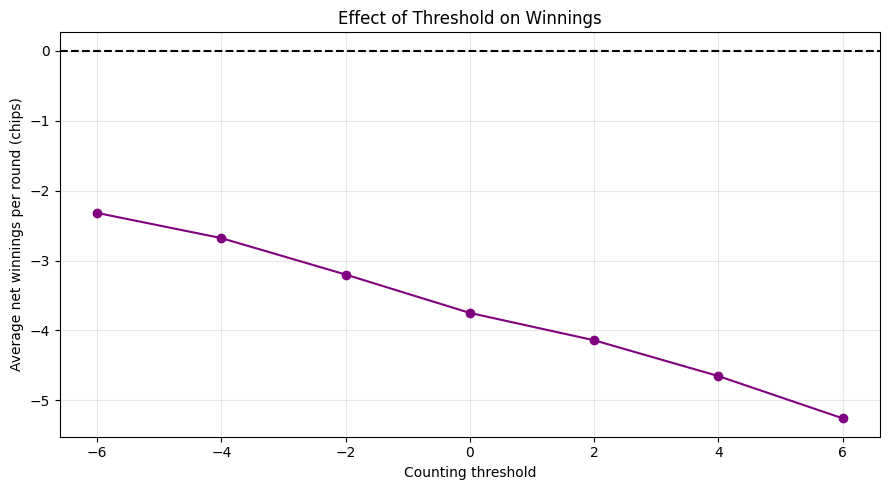

In [10]:
#9
thresholds = [-6, -4, -2, 0, 2, 4, 6]

threshold_results = {}
rows = []

for threshold in thresholds:
    result = run_experiment(
        strategy_class=CountingPlayer,
        threshold=threshold,
        seed_start=1000
    )

    threshold_results[threshold] = result

    rows.append({
        "Threshold": threshold,
        "Average final chips": result["mean_final_chips"],
        "Average net winnings": result["mean_net"],
        "Average per round": result["mean_per_round"],
        "SD net winnings": result["sd_net"],
        "P(net win)": result["prob_win"],
        "P(net loss)": result["prob_loss"],
        "P(break even)": result["prob_break_even"]
    })

threshold_table = pd.DataFrame(rows)

print(threshold_table.round(4).to_string(index=False))

best_row = threshold_table["Average per round"].idxmax()
best_threshold = int(threshold_table.loc[best_row, "Threshold"])

print(f"\nBest threshold in this experiment: {best_threshold}")
print("This is the best tested value, not a proven global optimum.")

plt.figure(figsize=(9, 5))
plt.plot(
    threshold_table["Threshold"],
    threshold_table["Average per round"],
    marker="o",
    color="purple"
)
plt.axhline(0, color="black", linestyle="--")
plt.xticks(thresholds)
plt.xlabel("Counting threshold")
plt.ylabel("Average net winnings per round (chips)")
plt.title("Effect of Threshold on Winnings")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

       Strategy  Average final chips  Average net winnings  Average per round  SD net winnings  P(net win)  P(net loss)
Dealer strategy              4978.25                -21.75             -0.435          61.7439        0.34         0.61
  Counting (-6)              4889.55               -110.45             -2.209          74.5495        0.07         0.92
   New strategy              4986.90                -13.10             -0.262          63.7775        0.41         0.54

The new strategy increased average winnings by 1.9470 chips per round compared with the selected counting strategy.
This conclusion describes these simulations; results can vary.


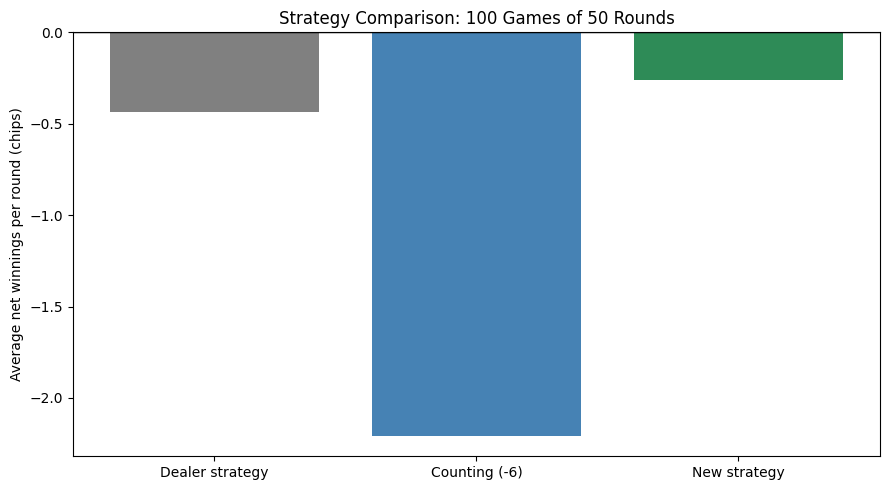

In [11]:
#10
class NewStrategyPlayer(Player):
    def wants_hit(self, dealer_upcard=None):
        total = self.hand.total()

        # Determine whether an ace still counts as 11.
        raw_total = sum(card.value for card in self.hand.cards)
        aces = sum(card.rank == "A" for card in self.hand.cards)

        while raw_total > 21 and aces > 0:
            raw_total -= 10
            aces -= 1

        soft_hand = aces > 0

        if total >= 21:
            return False

        if soft_hand:
            return total < 18

        if total <= 11:
            return True

        if total >= 17:
            return False

        dealer_value = dealer_upcard.value

        if total == 12:
            return dealer_value not in (4, 5, 6)

        # Remaining hard totals are 13–16.
        return dealer_value not in (2, 3, 4, 5, 6)



comparison_specs = [
    ("Dealer strategy", Dealer, None),
    (f"Counting ({best_threshold})", CountingPlayer, best_threshold),
    ("New strategy", NewStrategyPlayer, None)
]

comparison_results = {}
comparison_rows = []

for name, strategy_class, threshold in comparison_specs:
    result = run_experiment(
        strategy_class=strategy_class,
        threshold=threshold,
        seed_start=10000
    )

    comparison_results[name] = result

    comparison_rows.append({
        "Strategy": name,
        "Average final chips": result["mean_final_chips"],
        "Average net winnings": result["mean_net"],
        "Average per round": result["mean_per_round"],
        "SD net winnings": result["sd_net"],
        "P(net win)": result["prob_win"],
        "P(net loss)": result["prob_loss"]
    })

comparison_table = pd.DataFrame(comparison_rows)

print(comparison_table.round(4).to_string(index=False))

counting_name = f"Counting ({best_threshold})"

difference = (
    comparison_results["New strategy"]["mean_per_round"]
    - comparison_results[counting_name]["mean_per_round"]
)

if difference > 0:
    print(
        f"\nThe new strategy increased average winnings by "
        f"{difference:.4f} chips per round compared with "
        f"the selected counting strategy."
    )
elif difference < 0:
    print(
        f"\nThe new strategy decreased average winnings by "
        f"{abs(difference):.4f} chips per round compared with "
        f"the selected counting strategy."
    )
else:
    print("\nBoth strategies had the same average winnings per round.")

print("This conclusion describes these simulations; results can vary.")

plt.figure(figsize=(9, 5))
plt.bar(
    comparison_table["Strategy"],
    comparison_table["Average per round"],
    color=["gray", "steelblue", "seagreen"]
)
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Average net winnings per round (chips)")
plt.title("Strategy Comparison: 100 Games of 50 Rounds")
plt.tight_layout()
plt.show()